# 11 · Nearest neighbours combined with popularity (work package 3, core problem 1)

**Work package 3** of the [implementation plan](../../research/implementation_plan.md). The model is the fixed
combination of the project plan (section 6.1):

$$\text{score}(u, i) = w\,\tilde p_i + (1 - w)\,\tilde r_{ui}$$

- $p_i$: the number of accounts that traded token $i$ in the 14 days before $t$ (the baseline's popularity),
- $r_{ui} = \sum_{j \in H_u} s_{ji}$: how similar $i$ is to the tokens $H_u$ the account traded, where $s_{ji}$ is the
  cosine of the two tokens' account sets with shrinkage $\lambda$, and only the $k$ most similar tokens of each
  token are kept,
- the tilde scales each score to a maximum of 1 per account.

With $w = 1$ this is exactly the baseline, with $w = 0$ it is neighbours alone.

**Procedure.** The settings $k$, $\lambda$ and $w$ are chosen on the 10 **Dev A** points only. The chosen model is
then compared with the baseline on the 11 **Dev B** points, which played no part in the choice.

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd

import plots
import protocol as pc
import stats
import token_data as td
import tuning

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = pc.RESULTS_DIR / "wp3"
OUT.mkdir(parents=True, exist_ok=True)
CONFIG = pc.RESULTS_DIR.parent / "configs" / "wp3_knn.json"

legs = td.load_legs()

## 1. The grid, evaluated on Dev A

| Setting | Values |
| --- | --- |
| $k$ (neighbours kept per token) | 10, 25, 50, 100, 200 |
| $\lambda$ (shrinkage) | 0, 1, 5, 10, 25, 50 |
| $w$ (weight of popularity) | 0, 0.1, …, 1.0 |

330 settings × 10 points. `tuning.blend_grid` computes the neighbour scores once per ($k$, $\lambda$) and reuses
them for every $w$; a test checks that it gives exactly the recall of `protocol.run` with `pool_recsys.Blend`.
The grid takes a while, so its result is saved and read back when the notebook is run again.

In [2]:
KS = [10, 25, 50, 100, 200]
SHRINKS = [0, 1, 5, 10, 25, 50]
WEIGHTS = [round(0.1 * i, 1) for i in range(11)]
GRID_FILE = OUT / "grid_dev_a.csv"

if GRID_FILE.exists():
    grid = pd.read_csv(GRID_FILE, parse_dates=["point"])
    print(f"Read {len(grid):,} rows from {GRID_FILE.name}")
else:
    parts = []
    for t in pc.POINTS["dev_a"]:
        task = pc.load_task(legs, t)
        window = task.history(pc.REFERENCE_DAYS)
        parts.append(tuning.blend_grid(task, window, window, KS, SHRINKS, WEIGHTS))
        print(f"  {t:%d %b}: done ({len(task.eval_rows):,} accounts)", flush=True)
    grid = pd.concat(parts, ignore_index=True)
    grid.to_csv(GRID_FILE, index=False)

  02 Jul: done (9,606 accounts)


  04 Jul: done (11,916 accounts)


  06 Jul: done (13,922 accounts)


  08 Jul: done (6,685 accounts)


  10 Jul: done (5,675 accounts)


  12 Jul: done (5,091 accounts)


  14 Jul: done (5,614 accounts)


  16 Jul: done (5,626 accounts)


  18 Jul: done (4,210 accounts)


  20 Jul: done (5,137 accounts)


Mean recall@10 over the 10 Dev A points for every setting; the 10 best:

In [3]:
mean = grid.groupby(["k", "shrink", "weight"], as_index=False)[["recall", "recall_1", "recall_2-4", "recall_5+"]].mean()
mean.sort_values("recall", ascending=False).head(10)

,k,shrink,weight,recall,recall_1,recall_2-4,recall_5+
324,200,50,0.5000,0.1904,0.2519,0.2112,0.1311
325,200,50,0.6000,0.1875,0.2552,0.2124,0.1216
313,200,25,0.5000,0.1863,0.2473,0.2063,0.1274
258,100,50,0.5000,0.1857,0.2493,0.2052,0.1260
314,200,25,0.6000,0.1852,0.2520,0.2112,0.1195
259,100,50,0.6000,0.1834,0.2534,0.2078,0.1168
323,200,50,0.4000,0.1827,0.2370,0.1985,0.1305
302,200,10,0.5000,0.1826,0.2426,0.2008,0.1254
247,100,25,0.5000,0.1821,0.2445,0.2009,0.1232
303,200,10,0.6000,0.1819,0.2478,0.2070,0.1170


How recall depends on the weight $w$, for the best $k$ and $\lambda$. The left end is neighbours alone, the right
end the baseline.

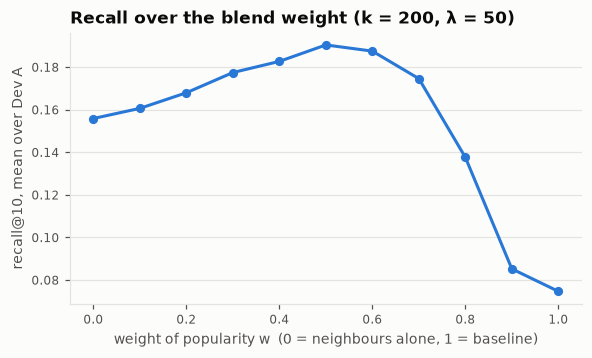

,319,320,321,322,323,324,325,326,327,328,329
weight,0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.0000
recall,0.1559,0.1606,0.1680,0.1775,0.1827,0.1904,0.1875,0.1746,0.1376,0.0852,0.0747


In [4]:
best_k, best_shrink = mean.sort_values("recall", ascending=False).iloc[0][["k", "shrink"]]
curve = mean[(mean["k"] == best_k) & (mean["shrink"] == best_shrink)]

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(curve["weight"], curve["recall"], marker="o", color=plots.colour("fixed blend"))
ax.set_xlabel("weight of popularity w  (0 = neighbours alone, 1 = baseline)")
ax.set_ylabel("recall@10, mean over Dev A")
ax.set_title(f"Recall over the blend weight (k = {best_k:.0f}, λ = {best_shrink:g})")
plt.show()
curve[["weight", "recall"]].T

## 2. The choice

The rule fixed in the implementation plan: the highest mean recall on Dev A; among settings within 0.002 of it,
the simpler one: fewer neighbours, then more shrinkage, then more weight on popularity.

In [5]:
chosen = tuning.best_setting(grid, ["k", "shrink", "weight"], {"k": "small", "shrink": "large", "weight": "large"})
settings = {"k": int(chosen["k"]), "shrink": float(chosen["shrink"]), "weight": float(chosen["weight"])}
CONFIG.parent.mkdir(exist_ok=True)
CONFIG.write_text(json.dumps({**settings, "chosen_on": "dev_a", "mean_recall_dev_a": round(float(chosen["recall"]), 4)}, indent=2))
print(f"Chosen on Dev A: {settings}, mean recall {chosen['recall']:.4f}")
print(f"Written to {CONFIG.relative_to(pc.RESULTS_DIR.parent)}")

Chosen on Dev A: {'k': 200, 'shrink': 50.0, 'weight': 0.5}, mean recall 0.1904
Written to configs/wp3_knn.json


## 3. Dev B: the chosen blend against the baseline

Dev B was not used for the choice. The baseline's numbers come from notebook 10. Neighbours alone ($w = 0$, same
$k$ and $\lambda$) are shown as a reference.

In [6]:
DEV_B = pc.POINTS["dev_b"]
baseline_b = pd.read_csv(pc.RESULTS_DIR / "wp2" / "baseline_dev.csv", parse_dates=["point"]).query("part == 'dev_b'")
blend = pc.run("fixed blend", lambda task: tuning.fixed_blend_scorer(task, settings), legs, DEV_B)
alone = pc.run("neighbours alone", lambda task: tuning.fixed_blend_scorer(task, {**settings, "weight": 0.0}), legs, DEV_B)
blend.per_point.to_csv(OUT / "fixed_blend_dev_b.csv", index=False)
alone.per_point.to_csv(OUT / "neighbours_alone_dev_b.csv", index=False)

results = {"popularity (baseline)": baseline_b, "fixed blend": blend.per_point, "neighbours alone": alone.per_point}
comparison = stats.compare(results, baseline="popularity (baseline)")
comparison.to_csv(OUT / "compare_dev_b.csv", index=False)
comparison

  fixed blend                  22 Jul: recall@10 = 0.138  (5,117 users)


  fixed blend                  24 Jul: recall@10 = 0.126  (5,326 users)


  fixed blend                  26 Jul: recall@10 = 0.109  (7,117 users)


  fixed blend                  28 Jul: recall@10 = 0.110  (7,329 users)


  fixed blend                  30 Jul: recall@10 = 0.118  (7,255 users)


  fixed blend                  01 Aug: recall@10 = 0.141  (6,404 users)


... (13 outputs left out)

  neighbours alone             07 Aug: recall@10 = 0.101  (5,524 users)


  neighbours alone             09 Aug: recall@10 = 0.091  (5,553 users)


  neighbours alone             11 Aug: recall@10 = 0.100  (5,837 users)


,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
0,popularity (baseline),11,0.0936,0.0773,0.1053,NaN,NaN,NaN,NaN,NaN
1,fixed blend,11,0.1312,0.1092,0.1486,0.0376,0.0318,0.0432,11 of 11,0.0010
2,neighbours alone,11,0.0893,0.0732,0.1008,-0.0043,-0.0106,0.0018,4 of 11,0.5488


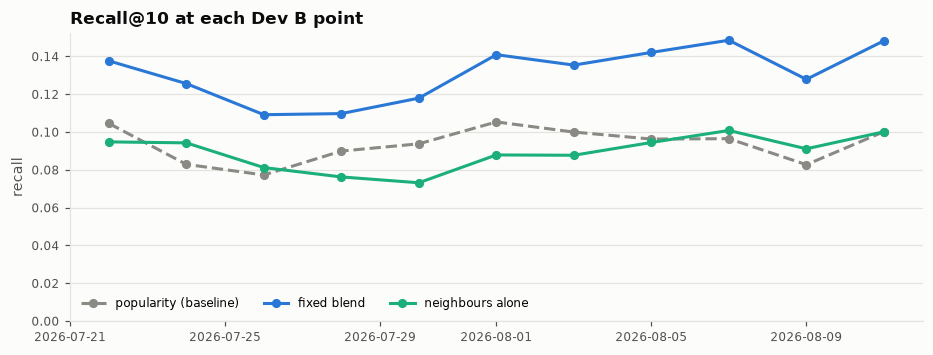

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.4))
plots.per_point_lines(ax, results)
ax.set_title("Recall@10 at each Dev B point")
plt.show()

## 4. Where does it help? By history size, without the head, and coverage

- **By history size:** accounts with 1, 2 to 4, and 5 or more tokens in the 14 days before $t$.
- **Without the head:** recall after removing from the target the most popular tokens that hold a third of the
  history's interactions (Cremonesi et al. 2010). A model cannot score here on popular tokens alone.
- **Coverage:** the share of all tokens that appear in at least one account's list.

In [8]:
columns = ["recall", "recall_1", "recall_2-4", "recall_5+", "recall_no_head", "coverage"]
pd.DataFrame({name: table[columns].mean() for name, table in results.items()}).T

,recall,recall_1,recall_2-4,recall_5+,recall_no_head,coverage
popularity (baseline),0.0936,0.1468,0.1085,0.0551,0.0000,0.0024
fixed blend,0.1312,0.1879,0.1457,0.0917,0.0440,0.0572
neighbours alone,0.0893,0.1137,0.0943,0.0736,0.0525,0.0703
